# Generating weights with a hypernetwork

Generate a family of two-dimensional linear maps from an angle.

A hypernetwork outputs the parameters of another network. Here the conditioning features are cosine and sine. A fixed linear generator arranges these values into a rotation matrix. The choice of features builds the group structure into the generator.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Construct the weights and test their behaviour

Inspect the arrays and the reference output. Each check describes a specific property of the constructed model.

largest orthogonality error 1.61e-16


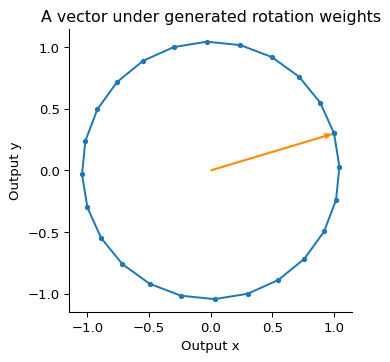

In [2]:
generator = np.array([[1.0, 0.0], [0.0, -1.0], [0.0, 1.0], [1.0, 0.0]])


def weights(angle):
    return (generator @ np.array([np.cos(angle), np.sin(angle)])).reshape(2, 2)


angles = np.linspace(0, 2 * np.pi, 25)
vec = np.array([1.0, 0.3])
path = np.stack([weights(t) @ vec for t in angles])
err = max(np.linalg.norm(weights(t).T @ weights(t) - np.eye(2)) for t in angles)
print(f"largest orthogonality error {err:.2e}")
assert np.allclose(weights(0.7) @ weights(0.2), weights(0.9))
fig, ax = plt.subplots(figsize=(4.6, 3.7), constrained_layout=True)
ax.plot(*path.T, "o-", ms=3)
ax.quiver(
    [0], [0], [vec[0]], [vec[1]], angles="xy", scale_units="xy", scale=1, color="darkorange"
)
ax.set(
    aspect="equal",
    xlabel="Output x",
    ylabel="Output y",
    title="A vector under generated rotation weights",
)
plt.show()

## Interpreting the result

The generated maps preserve length. A learned hypernetwork would need data or architectural constraints to acquire that property.

## Exercise

Add a separate input scale and state which test should now fail.

## References

[Ha, Dai and Le, HyperNetworks (2016)](https://arxiv.org/abs/1609.09106)